# Create new features inside a Feature-engine pipeline

This notebook is based on the pasted Feature-engine wine example. It uses the UCI Red Wine Quality data to create chemistry-inspired features, visualise them, and train a classifier inside one scikit-learn pipeline.

The target is converted to a binary label: quality ≤ 6 is low quality (`0`) and quality > 6 is higher quality (`1`). New features are created only inside the pipeline during the modelling section, so the same transformations are applied consistently to training and test data.

## Feature ideas used here

- `total_acidity` and `average_acidity`: combine fixed and volatile acidity.
- `total_minerals` and `average_minerals`: combine chlorides and sulphates.
- `non_free_sulfur_dioxide`: total sulfur dioxide minus free sulfur dioxide.
- `percentage_free_sulfur`: free sulfur dioxide divided by total sulfur dioxide.
- `percentage_salt_sulfur`: sulphates divided by free sulfur dioxide.

These formulas are hypotheses about the chemistry, not guaranteed improvements. Their value should be judged with validation data.

In [1]:
import importlib.util,subprocess,sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","feature_engine":"feature-engine"}
missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score,accuracy_score,classification_report
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold
from sklearn.pipeline import Pipeline
from feature_engine.creation import MathFeatures,RelativeFeatures
sns.set_theme(style="whitegrid",context="notebook")

## 1. Load the Red Wine Quality data

The notebook searches for a local `winequality-red.csv` and falls back to the UCI URL. The UCI file is semicolon-separated. A local copy is preferable for repeatable offline runs.

In [2]:
paths=[Path("winequality-red.csv"),Path("../winequality-red.csv"),Path("feature-engineering/pipelines/winequality-red.csv")]
local_path=next((p for p in paths if p.exists()),None)
url="https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
data=pd.read_csv(local_path if local_path is not None else url,sep=";")
print("Source:",local_path if local_path is not None else url)
print("Shape:",data.shape)
display(data.head())
display(data.describe().T.round(3))

Source: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


## 2. Explore target balance and distributions

Wine quality is an ordered score, but this example turns it into a binary classification problem. The first plots show how many examples are in each original quality class and how the continuous chemistry variables are distributed.

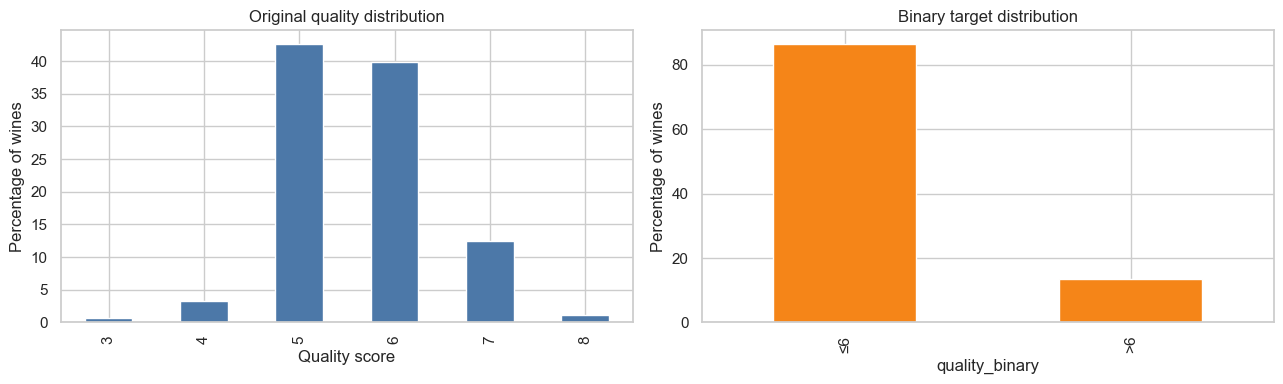

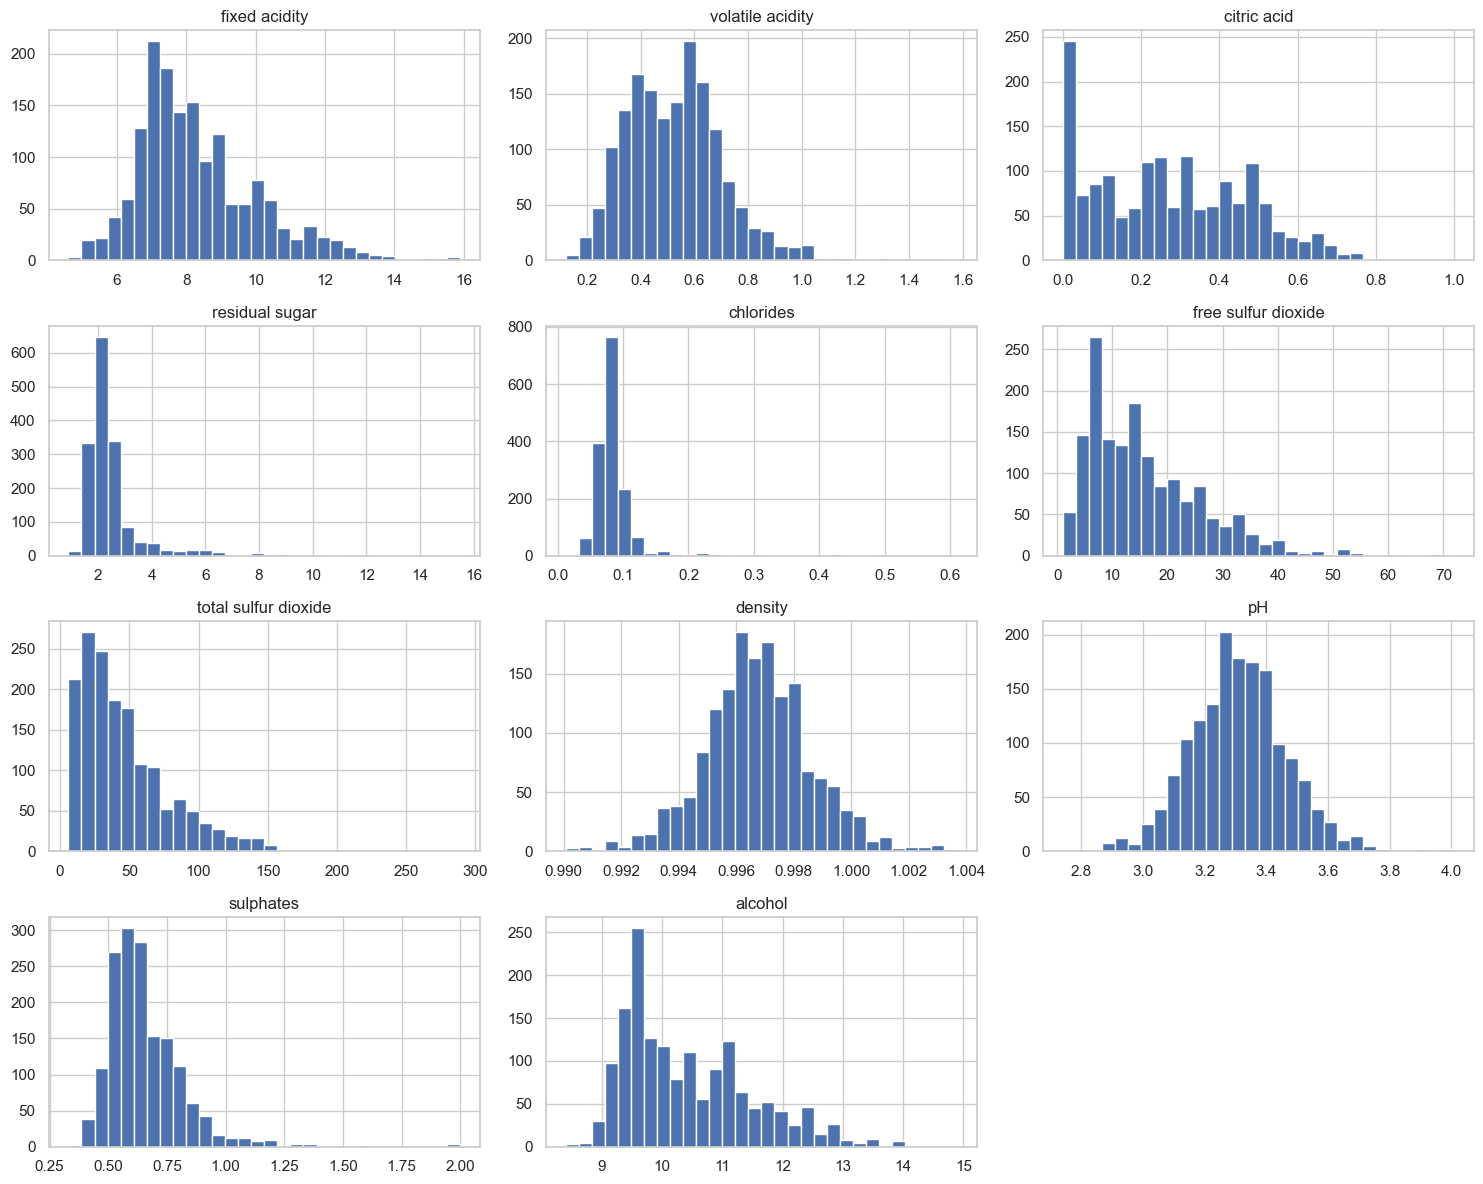

In [3]:
data["quality_binary"]=np.where(data["quality"]<=6,0,1)
fig,axes=plt.subplots(1,2,figsize=(13,4))
(data["quality"].value_counts(normalize=True).sort_index()*100).plot.bar(ax=axes[0],color="#4C78A8"); axes[0].set_title("Original quality distribution"); axes[0].set_xlabel("Quality score"); axes[0].set_ylabel("Percentage of wines")
(data["quality_binary"].value_counts(normalize=True).sort_index()*100).plot.bar(ax=axes[1],color="#F58518"); axes[1].set_title("Binary target distribution"); axes[1].set_xticks([0,1],["≤6",">6"]); axes[1].set_ylabel("Percentage of wines")
plt.tight_layout(); plt.show()
data.drop(columns=["quality","quality_binary"]).hist(bins=30,figsize=(15,12)); plt.tight_layout(); plt.show()

quality_binary,0,1
fixed acidity,8.237,8.847
volatile acidity,0.547,0.406
citric acid,0.254,0.376
residual sugar,2.512,2.709
chlorides,0.089,0.076
free sulfur dioxide,16.172,13.982
total sulfur dioxide,48.286,34.889
density,0.997,0.996
pH,3.315,3.289
sulphates,0.645,0.743


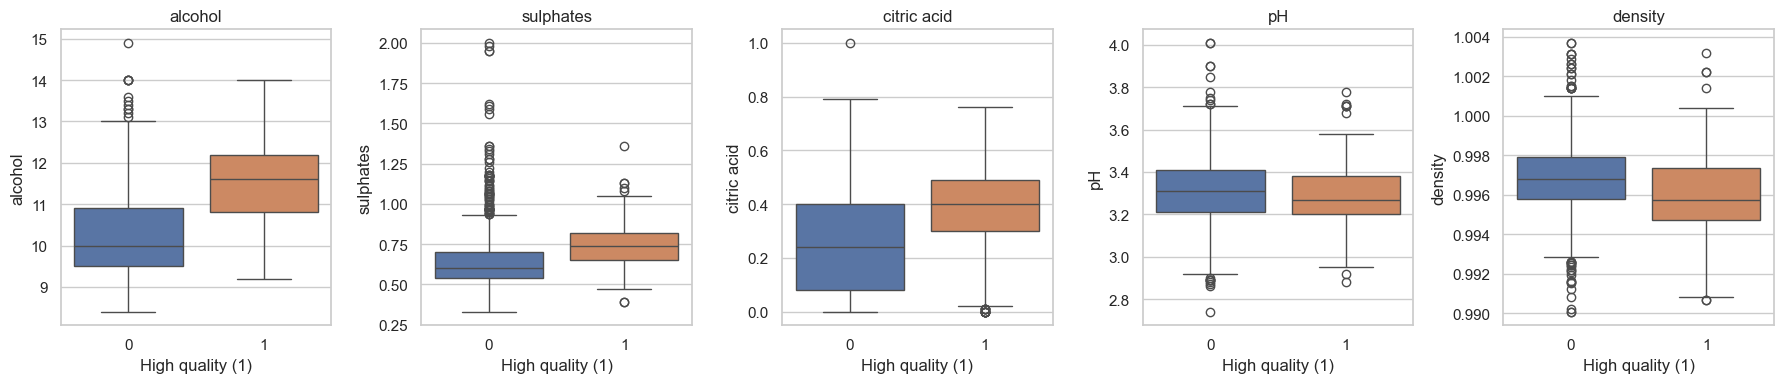

In [4]:
# Compare average chemistry values for the two target classes.
means=data.groupby("quality_binary").mean(numeric_only=True).T
display(means.round(3))
plot_vars=["alcohol","sulphates","citric acid","pH","density"]
fig,axes=plt.subplots(1,len(plot_vars),figsize=(18,4))
for ax,col in zip(axes,plot_vars):
    sns.boxplot(data=data,x="quality_binary",y=col,hue="quality_binary",legend=False,ax=ax); ax.set_title(col); ax.set_xlabel("High quality (1)")
plt.tight_layout(); plt.show()

## 3. Examine relationships that motivate feature creation

Scatter plots help us decide whether combinations or ratios might capture information that a single raw variable misses. The colour indicates the binary target and is used only for visual analysis.

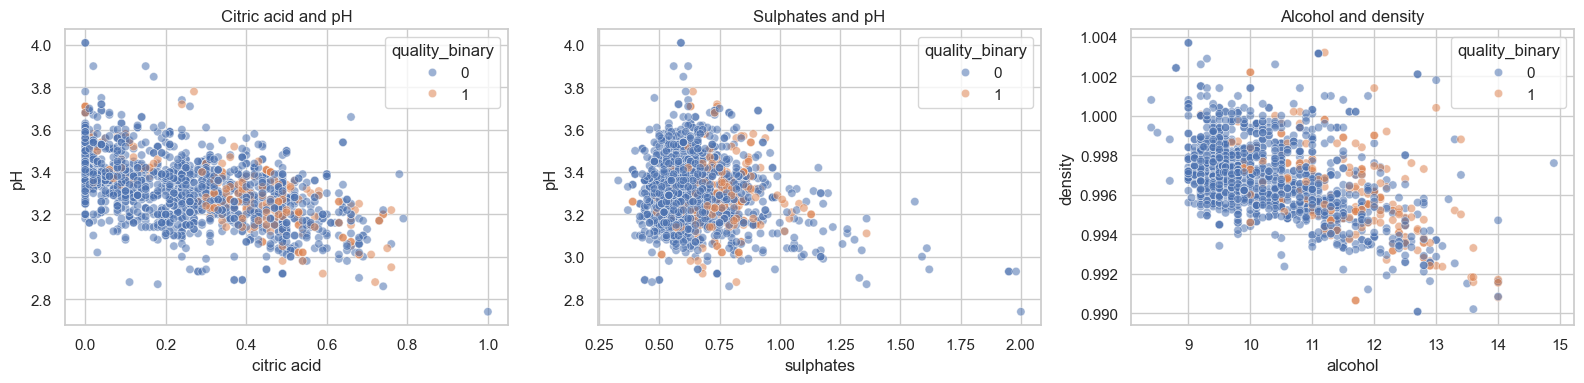

In [5]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
sns.scatterplot(data=data,x="citric acid",y="pH",hue="quality_binary",alpha=.55,ax=axes[0]); axes[0].set_title("Citric acid and pH")
sns.scatterplot(data=data,x="sulphates",y="pH",hue="quality_binary",alpha=.55,ax=axes[1]); axes[1].set_title("Sulphates and pH")
sns.scatterplot(data=data,x="alcohol",y="density",hue="quality_binary",alpha=.55,ax=axes[2]); axes[2].set_title("Alcohol and density")
plt.tight_layout(); plt.show()

## 4. Demonstrate the new features outside the model

This section makes the formulas visible on a copy of the data. In the final modelling workflow below, equivalent transformers run inside the pipeline instead of being applied to the complete dataset before splitting.

In [6]:
demo=data.drop(columns=["quality_binary"]).copy()
demo=MathFeatures(variables=["fixed acidity","volatile acidity"],func=["sum","mean"],new_variables_names=["total_acidity","average_acidity"]).fit_transform(demo)
demo=MathFeatures(variables=["chlorides","sulphates"],func=["sum","mean"],new_variables_names=["total_minerals","average_minerals"]).fit_transform(demo)
demo=RelativeFeatures(variables=["total sulfur dioxide"],reference=["free sulfur dioxide"],func=["sub"],missing_values="ignore").fit_transform(demo)
demo=RelativeFeatures(variables=["free sulfur dioxide"],reference=["total sulfur dioxide"],func=["div"],fill_value=0,missing_values="ignore").fit_transform(demo)
demo=RelativeFeatures(variables=["sulphates"],reference=["free sulfur dioxide"],func=["div"],fill_value=0,missing_values="ignore").fit_transform(demo)
new_columns=[c for c in demo.columns if c not in data.columns]
print("Created columns:",new_columns)
display(demo[new_columns].head())

Created columns: ['total_acidity', 'average_acidity', 'total_minerals', 'average_minerals', 'total sulfur dioxide_sub_free sulfur dioxide', 'free sulfur dioxide_div_total sulfur dioxide', 'sulphates_div_free sulfur dioxide']


,total_acidity,average_acidity,total_minerals,average_minerals,total sulfur dioxide_sub_free sulfur dioxide,free sulfur dioxide_div_total sulfur dioxide,sulphates_div_free sulfur dioxide
0,8.10,4.05,0.636,0.3180,23.0,0.323529,0.050909
1,8.68,4.34,0.778,0.3890,42.0,0.373134,0.027200
2,8.56,4.28,0.742,0.3710,39.0,0.277778,0.043333
3,11.48,5.74,0.655,0.3275,43.0,0.283333,0.034118
4,8.10,4.05,0.636,0.3180,23.0,0.323529,0.050909


In [ ]:
# Visualise distributions of the named mathematical features.
named=["total_acidity","average_acidity","total_minerals","average_minerals"]
long=demo[named].assign(quality_binary=data["quality_binary"]).melt(id_vars="quality_binary")
g=sns.FacetGrid(long,col="variable",hue="quality_binary",col_wrap=2,sharex=False,sharey=False,height=3.5)
g.map_dataframe(sns.histplot,kde=True,alpha=.45); g.add_legend(); plt.show()

## 5. Build the complete machine-learning pipeline

The target is removed before splitting. Each creation transformer adds columns and leaves its input columns available. `RelativeFeatures` uses `fill_value=0` for division-by-zero cases; this makes the transformation finite and explicit rather than allowing infinity to enter the classifier.

In [7]:
X=data.drop(columns=["quality","quality_binary"]).copy()
y=data["quality_binary"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=0,stratify=y)
pipe=Pipeline(steps=[
    ("acidity",MathFeatures(variables=["fixed acidity","volatile acidity"],func=["sum","mean"],new_variables_names=["total_acidity","average_acidity"])),
    ("minerals",MathFeatures(variables=["chlorides","sulphates"],func=["sum","mean"],new_variables_names=["total_minerals","average_minerals"])),
    ("non_free_sulfur",RelativeFeatures(variables=["total sulfur dioxide"],reference=["free sulfur dioxide"],func=["sub"],missing_values="ignore")),
    ("free_sulfur_ratio",RelativeFeatures(variables=["free sulfur dioxide"],reference=["total sulfur dioxide"],func=["div"],fill_value=0,missing_values="ignore")),
    ("salt_sulfur_ratio",RelativeFeatures(variables=["sulphates"],reference=["free sulfur dioxide"],func=["div"],fill_value=0,missing_values="ignore")),
    ("gbm",GradientBoostingClassifier(n_estimators=100,max_depth=2,random_state=1))
])
print("Train/test shapes:",X_train.shape,X_test.shape)
pipe

Train/test shapes: (1279, 11) (320, 11)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('acidity', ...), ('minerals', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variables,"['fixed acidity', 'volatile acidity']"
,func,"['sum', 'mean']"
,new_variables_names,"['total_acidity', 'average_acidity']"
,missing_values,'raise'
,drop_original,False
,variables,"['chlorides', 'sulphates']"
,func,"['sum', 'mean']"


## 6. Fit and evaluate the pipeline

The model sees raw columns plus the engineered columns created by the preceding steps. Because the creation steps are inside the pipeline, there is no separate transformation call to forget when predicting test data or future wines.

In [8]:
pipe.fit(X_train,y_train)
train_prob=pipe.predict_proba(X_train)[:,1]
test_prob=pipe.predict_proba(X_test)[:,1]
train_pred=(train_prob>=.5).astype(int); test_pred=(test_prob>=.5).astype(int)
print("Train ROC-AUC:",round(roc_auc_score(y_train,train_prob),4))
print("Test ROC-AUC:",round(roc_auc_score(y_test,test_prob),4))
print("Test accuracy:",round(accuracy_score(y_test,test_pred),4))
print(classification_report(y_test,test_pred,target_names=["quality ≤6","quality >6"]))

Train ROC-AUC: 0.956
Test ROC-AUC: 0.8876
Test accuracy: 0.8812
              precision    recall  f1-score   support

  quality ≤6       0.92      0.95      0.93       277
  quality >6       0.58      0.44      0.50        43

    accuracy                           0.88       320
   macro avg       0.75      0.70      0.72       320
weighted avg       0.87      0.88      0.87       320



## 7. Cross-validation and feature importance

A single holdout score can be noisy. Stratified cross-validation estimates how consistently the complete pipeline performs on different training/validation partitions. Feature importance is then inspected using the final classifier and the columns produced by the fitted creation steps.

,metric,mean,std
0,train ROC-AUC,0.9576,0.0040
1,validation ROC-AUC,0.8999,0.0188
2,validation accuracy,0.8912,0.0117


,importance
alcohol,0.377048
volatile acidity,0.137350
total_minerals,0.059161
total sulfur dioxide,0.052772
average_minerals,0.048295
sulphates,0.047956
residual sugar,0.036503
citric acid,0.036357
sulphates_div_free sulfur dioxide,0.033193
free sulfur dioxide_div_total sulfur dioxide,0.025828


/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_7516/54084015.py:8: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#4C78A8'` for the same effect.

  sns.barplot(x=importance.head(15).values,y=importance.head(15).index,hue=importance.head(15).index,legend=False,color="#4C78A8")


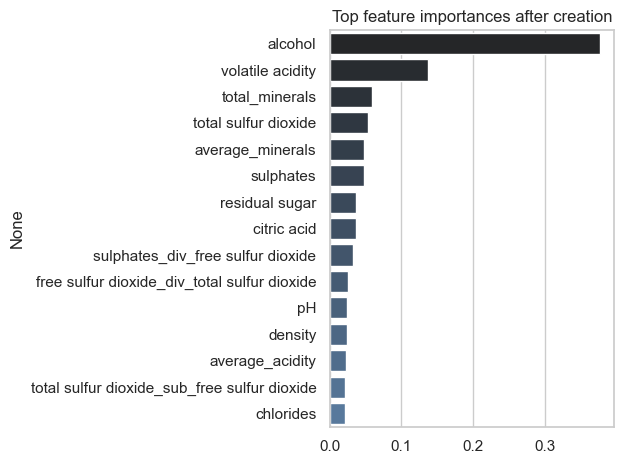

In [9]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores=cross_validate(pipe,X,y,cv=cv,scoring={"roc_auc":"roc_auc","accuracy":"accuracy"},return_train_score=True)
cv_summary=pd.DataFrame({"metric":["train ROC-AUC","validation ROC-AUC","validation accuracy"],"mean":[scores["train_roc_auc"].mean(),scores["test_roc_auc"].mean(),scores["test_accuracy"].mean()],"std":[scores["train_roc_auc"].std(),scores["test_roc_auc"].std(),scores["test_accuracy"].std()]})
display(cv_summary.round(4))
transformed_train=pipe[:-1].transform(X_train)
importance=pd.Series(pipe.named_steps["gbm"].feature_importances_,index=transformed_train.columns).sort_values(ascending=False)
display(importance.head(15).to_frame("importance"))
sns.barplot(x=importance.head(15).values,y=importance.head(15).index,hue=importance.head(15).index,legend=False,color="#4C78A8")
plt.title("Top feature importances after creation"); plt.tight_layout(); plt.show()

## 8. Interpret and use the result

The engineered variables are domain hypotheses: acidity sums, mineral summaries, sulfur differences, and sulfur ratios. A useful feature may capture a relationship that is awkward for a model to learn from separate columns, but it may also duplicate information or amplify measurement noise.

Keep the full fitted pipeline when deploying the model. Do not create features on the full dataset before cross-validation, because that can make validation performance optimistic. Check for division-by-zero, missing values, distribution drift, and whether a newly created feature improves validation performance over the raw-feature baseline.

### Summary

This notebook recreates the attached wine feature-creation example with the current Feature-engine creation API. It creates seven chemistry-inspired features, visualises their distributions, trains a Gradient Boosting classifier inside a pipeline, evaluates holdout and cross-validation performance, and reports feature importance.